# Modelo predictivo – OLS final

Modelo elegido en `Training.ipynb` (OLS), ajustado con todos los datos y con la imputación correspondiente. Este notebook hace las veces del modelo en producción: muestra cómo maneja datos faltantes, categorías nuevas, valores fuera de rango, predicciones negativas y el embudo de varianza, y reporta su desempeño y p-valores.

## 1. Configuración y fórmula del modelo

In [1]:
import sys
import warnings
from pathlib import Path

# Raíz del repositorio en el path, para importar model_pipeline desde notebooks/
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "model_pipeline").is_dir())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.nonparametric.smoothers_lowess import lowess

from model_pipeline import config
from model_pipeline.model import ModeloTiempoEntrega
from model_pipeline.preprocessing import cargar_datos

df = cargar_datos()

NUMERICAS, CATEGORICAS, TARGET = config.NUMERICAS, config.CATEGORICAS, config.TARGET
# Términos del modelo OLS elegido en Training.ipynb (selección forward, criterio RMSE_cv)
TERMINOS = config.TERMINOS_POR_DEFECTO
FORMULA = f"{TARGET} ~ " + " + ".join(TERMINOS)
print(FORMULA)


Delivery_Time_min ~ Distance_km + Preparation_Time_min + C(Traffic_Level) + C(Weather) + Courier_Experience_yrs


## 2. Clase del modelo

La clase `ModeloTiempoEntrega` vive en `model_pipeline/model.py`: es el **mismo código** que usan el pipeline (`run_pipeline.py`) y la API. Encapsula la imputación, la validación de entrada, el ajuste, las alertas y los intervalos.

In [2]:
print(ModeloTiempoEntrega.__doc__)
print("Métodos:", [m for m in dir(ModeloTiempoEntrega) if not m.startswith("_")])


Regresión lineal (OLS) para el tiempo de entrega, lista para producción.

- Imputa faltantes con mediana/moda aprendidas en el ajuste.
- Trata categorías desconocidas como faltantes.
- Marca valores fuera del rango de entrenamiento y recorta predicciones < PRED_MINIMA.
- Da intervalos de predicción empíricos por tramo de duración (más anchos en pedidos largos),
  calculados con residuos fuera de muestra.
- Usa errores estándar robustos (HC3) para la inferencia.

Métodos: ['cargar', 'contribuciones', 'ficha', 'fit', 'formula', 'guardar', 'predict', 'resumen', 'variables_usadas']


## 3. Ajuste con todos los datos

In [3]:
modelo = ModeloTiempoEntrega(TERMINOS, n_tramos=4, nivel_intervalo=0.90).fit(df)

ficha = modelo.ficha()
for k, v in ficha.items():
    print(f"{k:20s}: {v}")

formula             : Delivery_Time_min ~ Distance_km + Preparation_Time_min + C(Traffic_Level) + C(Weather) + Courier_Experience_yrs
fecha_entrenamiento : 2026-11-17T13:31:42
n_entrenamiento     : 1000
metricas_cv         : {'MAE': 6.552, 'RMSE': 10.594, 'MAPE_%': 10.911, 'R2': 0.769}
nivel_intervalo     : 0.9
intervalos_por_tramo: [{'tramo': 0, 'pred_desde': 10.034, 'pred_hasta': 42.34, 'MAE': 3.821, 'q_inf': -5.346, 'q_sup': 6.869}, {'tramo': 1, 'pred_desde': 42.34, 'pred_hasta': 56.045, 'MAE': 5.175, 'q_inf': -9.523, 'q_sup': 7.752}, {'tramo': 2, 'pred_desde': 56.045, 'pred_hasta': 70.697, 'MAE': 7.887, 'q_inf': -13.525, 'q_sup': 14.948}, {'tramo': 3, 'pred_desde': 70.697, 'pred_hasta': 103.271, 'MAE': 9.323, 'q_inf': -17.224, 'q_sup': 15.442}]
imputacion          : {'Distance_km': 10.19, 'Preparation_Time_min': 17.0, 'Courier_Experience_yrs': 5.0, 'Weather': 'Clear', 'Traffic_Level': 'Medium', 'Time_of_Day': 'Morning', 'Vehicle_Type': 'Bike'}
niveles             : {'Weather': ['Cl

## 4. Imputación de datos faltantes

Mediana para numéricas y moda para categóricas, aprendidas con todos los datos. En producción, cualquier faltante se rellena con estos valores y se marca en la columna `alerta`.

In [4]:
print("=== Valores de imputación aprendidos con todos los datos ===")
print(pd.Series(modelo.imputacion_))

print("\n=== Datos faltantes en el dataset completo ===")
print(df[NUMERICAS + CATEGORICAS].isnull().sum())

=== Valores de imputación aprendidos con todos los datos ===
Distance_km                 10.19
Preparation_Time_min         17.0
Courier_Experience_yrs        5.0
Weather                     Clear
Traffic_Level              Medium
Time_of_Day               Morning
Vehicle_Type                 Bike
dtype: object

=== Datos faltantes en el dataset completo ===
Distance_km                0
Preparation_Time_min       0
Courier_Experience_yrs    30
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
dtype: int64


## 5. Desempeño esperado

Al usar todos los datos no queda un test separado: el desempeño esperado se estima con predicciones fuera de muestra (validación cruzada de 10 folds).

=== Desempeño esperado (CV 10 folds, predicciones fuera de muestra, todos los datos) ===
MAE        6.552
RMSE      10.594
MAPE_%    10.911
R2         0.769
dtype: float64


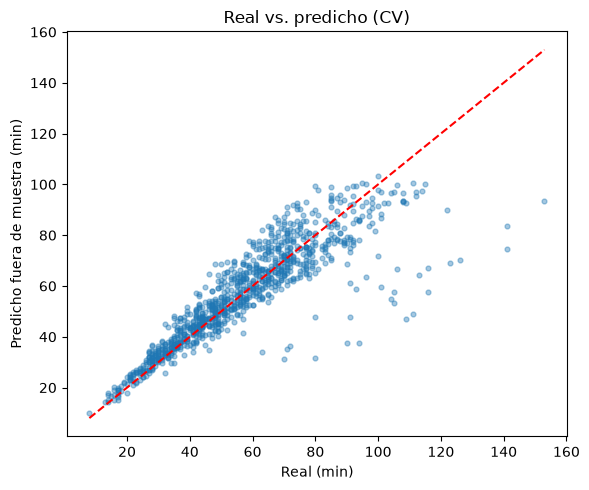

In [5]:
print("=== Desempeño esperado (CV 10 folds, predicciones fuera de muestra, todos los datos) ===")
print(pd.Series(modelo.metricas_cv_).round(3))

oof = modelo.oof_
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(oof["real"], oof["pred_oof"], alpha=0.4, s=12)
lim = [oof["real"].min(), oof["real"].max()]
ax.plot(lim, lim, color="red", linestyle="--")
ax.set(xlabel="Real (min)", ylabel="Predicho fuera de muestra (min)", title="Real vs. predicho (CV)")
plt.tight_layout()
plt.show()

## 6. Coeficientes y p-valores (errores robustos)

In [6]:
# Datos completos imputados (mismo esquema que el modelo)
df_full_imp = modelo._preparar(df)

# 1. Ajustes: clásico vs. robustos
ajustes = {
    "Clásico": smf.ols(FORMULA, data=df_full_imp).fit(),
    "HC0": smf.ols(FORMULA, data=df_full_imp).fit(cov_type="HC0"),
    "HC1": smf.ols(FORMULA, data=df_full_imp).fit(cov_type="HC1"),
    "HC3": smf.ols(FORMULA, data=df_full_imp).fit(cov_type="HC3"),
}
modelo_robusto = ajustes["HC3"]

# 2. Comparar errores estándar y p-valores
comp = pd.DataFrame({"coef": ajustes["Clásico"].params})
for nombre, m in ajustes.items():
    comp[f"EE_{nombre}"] = m.bse
for nombre, m in ajustes.items():
    comp[f"p_{nombre}"] = m.pvalues
comp["ratio_EE_HC3/Clásico"] = comp["EE_HC3"] / comp["EE_Clásico"]
comp["cambia_significancia"] = (comp["p_Clásico"] < 0.05) != (comp["p_HC3"] < 0.05)

pd.set_option("display.width", 200)
print("=== Errores estándar y p-valores: clásicos vs. robustos ===")
print(comp.round(4).to_string())

=== Errores estándar y p-valores: clásicos vs. robustos ===
                               coef  EE_Clásico  EE_HC0  EE_HC1  EE_HC3  p_Clásico   p_HC0  p_HC1  p_HC3  ratio_EE_HC3/Clásico  cambia_significancia
Intercept                   17.4915      1.4181  1.4376  1.4449  1.4547     0.0000  0.0000   0.00  0.000                1.0258                 False
C(Traffic_Level)[T.Low]    -11.8519      0.9259  0.9659  0.9708  0.9780     0.0000  0.0000   0.00  0.000                1.0562                 False
C(Traffic_Level)[T.Medium]  -6.1856      0.9122  0.9391  0.9438  0.9504     0.0000  0.0000   0.00  0.000                1.0419                 False
C(Weather)[T.Foggy]          7.3383      1.1422  1.2900  1.2965  1.3089     0.0000  0.0000   0.00  0.000                1.1460                 False
C(Weather)[T.Rainy]          4.9164      0.8784  0.9161  0.9207  0.9244     0.0000  0.0000   0.00  0.000                1.0524                 False
C(Weather)[T.Snowy]          9.4841      1.173

In [7]:
# 3. Resumen completo con HC3
print(modelo_robusto.summary())

# 4. Tabla final para reportar (coeficientes + IC robustos)
ic = modelo_robusto.conf_int()
tabla_reporte = pd.DataFrame({
    "coef": modelo_robusto.params,
    "EE_HC3": modelo_robusto.bse,
    "z": modelo_robusto.tvalues,
    "p_valor": modelo_robusto.pvalues,
    "IC95_inf": ic[0],
    "IC95_sup": ic[1],
    "signif": np.select([modelo_robusto.pvalues < 0.001, modelo_robusto.pvalues < 0.01,
                         modelo_robusto.pvalues < 0.05], ["***", "**", "*"], ""),
})
print("\n=== Coeficientes con errores robustos HC3 ===")
print(tabla_reporte.round(4).to_string())

# 5. Significancia conjunta por variable (todas sus dummies juntas), robusta
print("\n=== Prueba de Wald conjunta por término (HC3) ===")
print(modelo_robusto.wald_test_terms(scalar=True).summary_frame().round(4))

                            OLS Regression Results                            
Dep. Variable:      Delivery_Time_min   R-squared:                       0.775
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                     434.5
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:32:15   Log-Likelihood:                -3767.6
No. Observations:                1000   AIC:                             7555.
Df Residuals:                     990   BIC:                             7604.
Df Model:                           9                                         
Covariance Type:                  HC3                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

## 7. Embudo de varianza

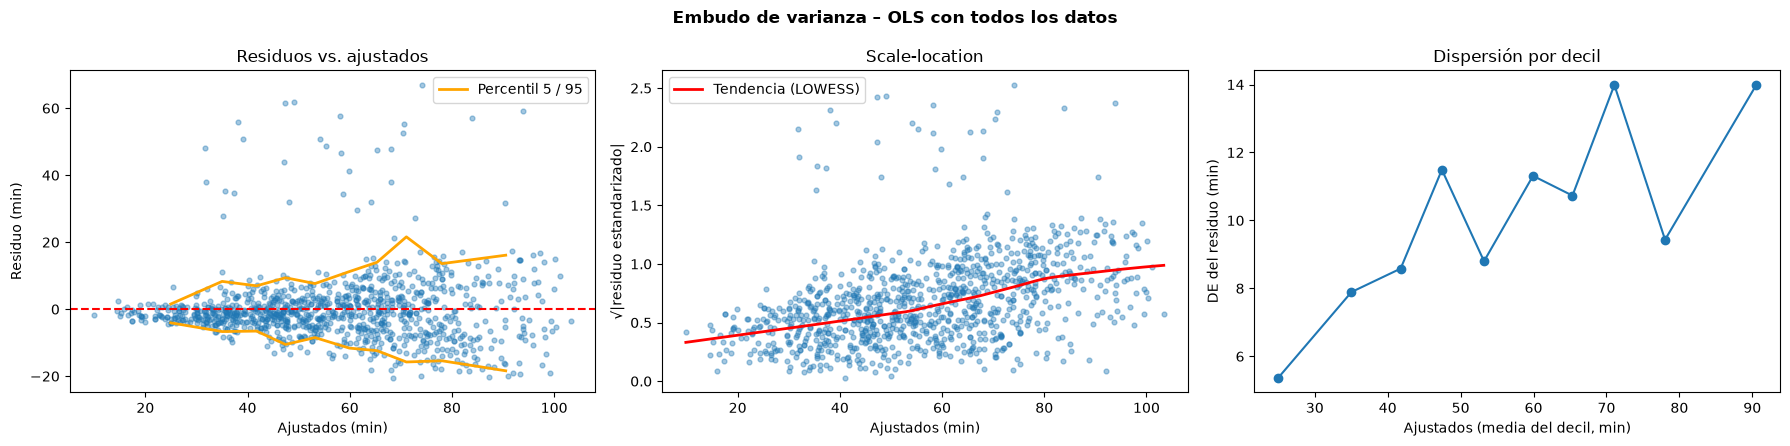

Breusch-Pagan: LM = 16.26 | p-valor = 0.0616  -> no hay evidencia de embudo


In [8]:
# Residuos del modelo ajustado con todos los datos
ajustados = np.asarray(modelo_robusto.fittedvalues)
residuos = np.asarray(modelo_robusto.resid)
est = modelo_robusto.get_influence().resid_studentized_internal

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Residuos vs. ajustados con bandas P5/P95 por decil
ax = axes[0]
ax.scatter(ajustados, residuos, alpha=0.4, s=12)
ax.axhline(0, color="red", linestyle="--")
tramos = pd.qcut(ajustados, 10)
bandas = pd.DataFrame({"x": ajustados, "r": residuos, "t": tramos}).groupby("t", observed=True).agg(
    x=("x", "mean"), p05=("r", lambda s: s.quantile(0.05)), p95=("r", lambda s: s.quantile(0.95)),
    sd=("r", "std"))
ax.plot(bandas["x"], bandas["p05"], color="orange", lw=2, label="Percentil 5 / 95")
ax.plot(bandas["x"], bandas["p95"], color="orange", lw=2)
ax.set(xlabel="Ajustados (min)", ylabel="Residuo (min)", title="Residuos vs. ajustados")
ax.legend()

# 2. Scale-location
ax = axes[1]
y_sl = np.sqrt(np.abs(est))
ax.scatter(ajustados, y_sl, alpha=0.4, s=12)
t = lowess(y_sl, ajustados, frac=0.4)
ax.plot(t[:, 0], t[:, 1], color="red", lw=2, label="Tendencia (LOWESS)")
ax.set(xlabel="Ajustados (min)", ylabel="√|residuo estandarizado|", title="Scale-location")
ax.legend()

# 3. Desviación estándar del residuo por decil
ax = axes[2]
ax.plot(bandas["x"], bandas["sd"], marker="o")
ax.set(xlabel="Ajustados (media del decil, min)", ylabel="DE del residuo (min)",
       title="Dispersión por decil")

plt.suptitle("Embudo de varianza – OLS con todos los datos", fontweight="bold")
plt.tight_layout()
plt.show()

lm_stat, lm_p, _, _ = het_breuschpagan(modelo_robusto.resid, modelo_robusto.model.exog)
print(f"Breusch-Pagan: LM = {lm_stat:.2f} | p-valor = {lm_p:.4f}  ->",
      "hay heterocedasticidad (embudo)" if lm_p < 0.05 else "no hay evidencia de embudo")

### Intervalos de predicción por tramo de duración

Como el error crece en los pedidos largos, los intervalos se calculan por tramo con los residuos fuera de muestra, en lugar de usar el intervalo constante del OLS.

=== Error e intervalos del 90% por tramo de duración predicha ===
       pred_desde  pred_hasta   MAE  q_inf  q_sup  ancho_intervalo
tramo                                                             
0           10.03       42.34  3.82  -5.35   6.87            12.22
1           42.34       56.04  5.18  -9.52   7.75            17.27
2           56.04       70.70  7.89 -13.53  14.95            28.47
3           70.70      103.27  9.32 -17.22  15.44            32.67

Cobertura (mitades cruzadas): 89.4%  (objetivo 90%)
tramo
0    89.2%
1    89.6%
2    90.0%
3    88.8%
Name: cobertura_por_tramo, dtype: str


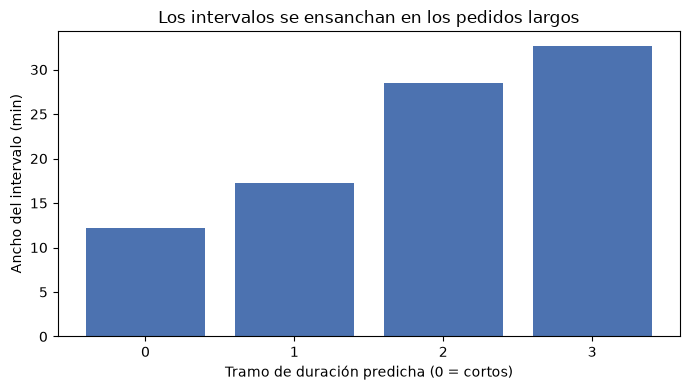

In [9]:
print(f"=== Error e intervalos del {modelo.nivel_intervalo:.0%} por tramo de duración predicha ===")
tabla_int = modelo.intervalos_.copy()
tabla_int["ancho_intervalo"] = tabla_int["q_sup"] - tabla_int["q_inf"]
print(tabla_int.round(2))

# Verificación honesta de la cobertura: los cuantiles se estiman con una mitad de los
# residuos fuera de muestra y la cobertura se mide en la otra mitad (y viceversa)
oof = modelo.oof_.copy()
oof["tramo"] = modelo._tramo(oof["pred_oof"])
a = (1 - modelo.nivel_intervalo) / 2
mitad = np.random.default_rng(17).permutation(len(oof)) % 2
oof["cubre"] = False
for h in (0, 1):
    estima, evalua = oof[mitad != h], oof[mitad == h]
    q = estima.groupby("tramo")["error"].quantile([a, 1 - a]).unstack()
    lo = evalua["tramo"].map(q[a])
    hi = evalua["tramo"].map(q[1 - a])
    oof.loc[evalua.index, "cubre"] = (evalua["error"] >= lo) & (evalua["error"] <= hi)

print(f"\nCobertura (mitades cruzadas): {oof['cubre'].mean():.1%}  (objetivo {modelo.nivel_intervalo:.0%})")
print(oof.groupby("tramo")["cubre"].mean().rename("cobertura_por_tramo").map("{:.1%}".format))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tabla_int.index.astype(str), tabla_int["ancho_intervalo"], color="#4C72B0")
ax.set(xlabel="Tramo de duración predicha (0 = cortos)", ylabel="Ancho del intervalo (min)",
       title="Los intervalos se ensanchan en los pedidos largos")
plt.tight_layout()
plt.show()

## 8. Casos especiales en producción

| Caso | Tratamiento |
|---|---|
| Datos faltantes | Se imputan con mediana/moda y se marca en `alerta` |
| Categorías nuevas | Aviso; se tratan como faltantes (moda) |
| Valores fuera de rango | Se predice igual, pero se marca en `alerta` (extrapolación) |
| Predicciones negativas | Se recortan a un mínimo de 1 minuto y se marca en `alerta` |

In [10]:
# Pedidos de ejemplo que cubren cada situación
nuevos = pd.DataFrame([
    # 1. Pedido normal
    {"Distance_km": 7.5, "Weather": "Rainy", "Traffic_Level": "High", "Time_of_Day": "Evening",
     "Vehicle_Type": "Bike", "Preparation_Time_min": 15, "Courier_Experience_yrs": 3},
    # 2. Datos faltantes
    {"Distance_km": 2.1, "Weather": None, "Traffic_Level": "Low", "Time_of_Day": "Morning",
     "Vehicle_Type": "Scooter", "Preparation_Time_min": 10, "Courier_Experience_yrs": None},
    # 3. Categoría nueva (no vista en el entrenamiento)
    {"Distance_km": 5.0, "Weather": "Hail", "Traffic_Level": "Medium", "Time_of_Day": "Night",
     "Vehicle_Type": "Drone", "Preparation_Time_min": 20, "Courier_Experience_yrs": 5},
    # 4. Valores fuera del rango de entrenamiento
    {"Distance_km": 45.0, "Weather": "Clear", "Traffic_Level": "Low", "Time_of_Day": "Afternoon",
     "Vehicle_Type": "Car", "Preparation_Time_min": 60, "Courier_Experience_yrs": 25},
    # 5. Caso extremo que podría dar una predicción negativa
    {"Distance_km": -5.0, "Weather": "Clear", "Traffic_Level": "Low", "Time_of_Day": "Morning",
     "Vehicle_Type": "Car", "Preparation_Time_min": 0, "Courier_Experience_yrs": 9},
], index=["normal", "faltantes", "categoria_nueva", "fuera_de_rango", "pred_negativa"])

pd.set_option("display.max_colwidth", None)
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    resultado = modelo.predict(nuevos)
for a in avisos:
    print("AVISO:", a.message)

# Predicción cruda (sin recorte) para ver el efecto del límite mínimo
cruda = modelo.modelo_.predict(modelo._preparar(nuevos))
resultado.insert(0, "prediccion_cruda", cruda.round(2))
resultado.round(2)

AVISO: Weather: valores desconocidos ['Hail'] -> se imputan con la moda


c:\Users\Lenovo\Documents\Prueba_p&g\model_pipeline\preprocessing.py:53: UserWarning: Weather: valores desconocidos ['Hail'] -> se imputan con la moda
  warnings.warn(f"{c}: valores desconocidos {sorted(d.loc[desconocidas, c].unique())} "


,prediccion_cruda,prediccion_min,limite_inf,limite_sup,alerta
normal,57.39,57.39,43.86,72.34,
faltantes,18.32,18.32,12.97,25.19,Courier_Experience_yrs imputada; Weather imputada
categoria_nueva,42.33,42.33,36.99,49.20,Weather imputada
fuera_de_rango,181.89,181.89,164.67,197.33,"Distance_km fuera de rango [0.59, 19.99]; Preparation_Time_min fuera de rango [5, 29]; Courier_Experience_yrs fuera de rango [0, 9]"
pred_negativa,-15.22,1.00,1.00,7.87,"Distance_km fuera de rango [0.59, 19.99]; Preparation_Time_min fuera de rango [5, 29]; predicción recortada a 1 min"


## 9. Uso del modelo

In [11]:
# Uso en "producción": recibir pedidos nuevos y predecir
pedidos = df.sample(5, random_state=17)[NUMERICAS + CATEGORICAS]
pd.concat([pedidos, modelo.predict(pedidos).round(2)], axis=1)

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,prediccion_min,limite_inf,limite_sup,alerta
786,18.33,5,5.0,Snowy,Medium,Morning,Scooter,77.17,59.95,92.61,
499,0.88,27,2.0,Rainy,Low,Night,Car,38.01,32.66,44.87,
930,7.34,22,5.0,Foggy,Medium,Afternoon,Bike,58.61,45.08,73.56,
217,17.13,19,1.0,Rainy,Low,Evening,Car,79.52,62.30,94.96,
803,17.51,15,3.0,Clear,Medium,Evening,Bike,76.22,59.00,91.67,
